<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Import-libraries" data-toc-modified-id="Import-libraries-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Import libraries</a></span></li><li><span><a href="#Define-function-to-plot-two-signals-and-define-window-for-cross-correlation" data-toc-modified-id="Define-function-to-plot-two-signals-and-define-window-for-cross-correlation-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Define function to plot two signals and define window for cross-correlation</a></span><ul class="toc-item"><li><span><a href="#Test" data-toc-modified-id="Test-2.1"><span class="toc-item-num">2.1&nbsp;&nbsp;</span>Test</a></span><ul class="toc-item"><li><span><a href="#P-wave-cross-correlation" data-toc-modified-id="P-wave-cross-correlation-2.1.1"><span class="toc-item-num">2.1.1&nbsp;&nbsp;</span>P wave cross-correlation</a></span></li><li><span><a href="#S-wave-cross-correlation" data-toc-modified-id="S-wave-cross-correlation-2.1.2"><span class="toc-item-num">2.1.2&nbsp;&nbsp;</span>S wave cross-correlation</a></span></li></ul></li></ul></li><li><span><a href="#Load-event-table" data-toc-modified-id="Load-event-table-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Load event table</a></span></li><li><span><a href="#Calculate-for-every-event-pair" data-toc-modified-id="Calculate-for-every-event-pair-4"><span class="toc-item-num">4&nbsp;&nbsp;</span>Calculate for every event pair</a></span><ul class="toc-item"><li><span><a href="#Parallel" data-toc-modified-id="Parallel-4.1"><span class="toc-item-num">4.1&nbsp;&nbsp;</span>Parallel</a></span><ul class="toc-item"><li><span><a href="#P-wave" data-toc-modified-id="P-wave-4.1.1"><span class="toc-item-num">4.1.1&nbsp;&nbsp;</span>P wave</a></span></li><li><span><a href="#S-wave" data-toc-modified-id="S-wave-4.1.2"><span class="toc-item-num">4.1.2&nbsp;&nbsp;</span>S wave</a></span></li></ul></li></ul></li></ul></div>

## Import libraries

In [1]:
# Fundamentals
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ObsPy related
from obspy import read, UTCDateTime
from obspy.signal.cross_correlation import correlate, xcorr_max

# Iteration
import multiprocessing as mp
from itertools import combinations
from tqdm import tqdm

# File related
from glob import glob
import os

plt.rcParams["figure.figsize"]=(20, 10)

## Define function to plot two signals and define window for cross-correlation

In [38]:
def cc_window_selection(station, eventdir1, eventdir2, pre_lag, post_lag, common_path, freqmin=1, freqmax=20, interp_samp=1000, comp="Z", plot=True):
    
    if comp=="Z": # P wave cross-correlation measurement
        
        sacfile1=glob(common_path+f"{eventdir1}/{eventdir1}.*.{station}.*Z.SAC")[0]
        sacfile2=glob(common_path+f"{eventdir2}/{eventdir2}.*.{station}.*Z.SAC")[0]
            
        tr1=read(sacfile1)[0].interpolate(sampling_rate=interp_samp, method="lanczos", a=20).detrend("demean").taper(0.05).filter("bandpass", freqmin=freqmin, freqmax=freqmax, corners=4, zerophase=True).detrend("demean").taper(0.05)
        tr2=read(sacfile2)[0].interpolate(sampling_rate=interp_samp, method="lanczos", a=20).detrend("demean").taper(0.05).filter("bandpass", freqmin=freqmin, freqmax=freqmax, corners=4, zerophase=True).detrend("demean").taper(0.05)
        
        # Phase arrival time
        ptime1=tr1.stats.starttime+tr1.stats.sac.a-tr1.stats.sac.b
        ptime2=tr2.stats.starttime+tr2.stats.sac.a-tr2.stats.sac.b
        
        time1, time2=ptime1, ptime2
        ot1, ot2=tr1.stats.starttime-tr1.stats.sac.b, tr2.stats.starttime-tr2.stats.sac.b
        
        # Slice around phase arrival time
        tr1_slice=tr1.copy().slice(ptime1-pre_lag, ptime1+post_lag).normalize()
        tr2_slice=tr2.copy().slice(ptime2-pre_lag, ptime2+post_lag).normalize()

        if plot==True:
            # Plotting
            plt.figure(figsize=(20, 6))
            plt.title(f"Station: {station} / [P - {pre_lag}s, P + {post_lag}s]", fontsize=25, pad=20)
            plt.plot(tr1_slice.times(), tr1_slice.data, color="r")
            plt.plot(tr2_slice.times(), tr2_slice.data, color="b")

            plt.axvline(x=pre_lag, color="k", linestyle="--")
            # plt.xticks(np.linspace(0, 2*lag, 11))
            plt.grid(axis="x")

            plt.show();
            
    elif comp in ["N", "E"]: # S wave cross-correlation measurement
        
        sacfile1=glob(common_path+f"{eventdir1}/{eventdir1}.*.{station}.*{comp}.SAC")[0]
        sacfile2=glob(common_path+f"{eventdir2}/{eventdir2}.*.{station}.*{comp}.SAC")[0]
            
        tr1=read(sacfile1)[0].interpolate(sampling_rate=interp_samp, method="lanczos", a=20).detrend("demean").taper(0.05).filter("bandpass", freqmin=freqmin, freqmax=freqmax, corners=4, zerophase=True).detrend("demean").taper(0.05)
        tr2=read(sacfile2)[0].interpolate(sampling_rate=interp_samp, method="lanczos", a=20).detrend("demean").taper(0.05).filter("bandpass", freqmin=freqmin, freqmax=freqmax, corners=4, zerophase=True).detrend("demean").taper(0.05)
        
        # Phase arrival time
        stime1=tr1.stats.starttime+tr1.stats.sac.t0-tr1.stats.sac.b
        stime2=tr2.stats.starttime+tr2.stats.sac.t0-tr2.stats.sac.b
        
        time1, time2=stime1, stime2
        ot1, ot2=tr1.stats.starttime-tr1.stats.sac.b, tr2.stats.starttime-tr2.stats.sac.b
        
        # Slice around phase arrival time
        tr1_slice=tr1.copy().slice(stime1-pre_lag, stime1+post_lag).normalize()
        tr2_slice=tr2.copy().slice(stime2-pre_lag, stime2+post_lag).normalize()

        if plot==True:
            # Plotting
            plt.figure(figsize=(20, 6))
            plt.title(f"Station: {station} / [S - {pre_lag}s, S + {post_lag}s]", fontsize=25, pad=20)
            plt.plot(tr1_slice.times(), tr1_slice.data, color="r")
            plt.plot(tr2_slice.times(), tr2_slice.data, color="b")

            plt.axvline(x=pre_lag, color="k", linestyle="--")
            # plt.xticks(np.linspace(0, 2*lag, 11))
            plt.grid(axis="x")

            plt.show();
        
    return [tr1, tr2, tr1_slice, tr2_slice, time1, time2, ot1, ot2]

In [39]:
def cc_measurement_revised_Pwave(tr1, tr2, pre_lag, post_lag, shift_samp, margin, plot=True):
    
    # Slice the first signal
    time1=tr1.stats.starttime+pre_lag
    tr1_slice=tr1.copy().slice(time1-pre_lag, time1+post_lag)
    
    # Slice the second signal while varying windows and calculate cross-correlation multiple times
    arrival_time=tr2.stats.starttime+tr2.stats.sac.a-tr2.stats.sac.b
        
    slide_list, shift_list, slide_cc_list=[], [], []
    
    for slide in np.arange(-margin, margin, 0.001):
        tr2_slice=tr2.copy().slice(arrival_time-pre_lag+slide, arrival_time+post_lag+slide)
        
        # Calculate cross-correlation
        cc_array=correlate(tr1_slice, tr2_slice, shift_samp)
        shift, coeff=xcorr_max(cc_array, abs_max=False)       
        
        shift_list.append(shift)
        slide_cc_list.append(coeff)
        slide_list.append(slide)
        
    max_index=np.argmax(slide_cc_list)
    slide_max=slide_list[max_index]
    shift_max=shift_list[max_index]
    tr2_slice=tr2.copy().slice(arrival_time-pre_lag+slide_max, arrival_time+post_lag+slide_max)
        
    if plot==True:
        # Plotting
        plt.figure(figsize=(20, 6))
        plt.plot(tr1_slice.times(), tr1_slice.normalize().data, color="r")
        plt.plot(tr2_slice.times()+shift_max*(1/tr1.stats.sampling_rate), tr2_slice.normalize().data, color="b")
        plt.grid(axis="x")

        plt.show();
        
    shift=np.round((shift_max/1000-slide_max), 3)
    coeff=slide_cc_list[max_index]
        
    return [shift, coeff]

In [40]:
def cc_measurement_revised_Swave(tr1, tr2, pre_lag, post_lag, shift_samp, margin, plot=True):
    
    # Slice the first signal
    time1=tr1.stats.starttime+pre_lag
    tr1_slice=tr1.copy().slice(time1-pre_lag, time1+post_lag)
    
    # Slice the second signal while varying windows and calculate cross-correlation multiple times
    arrival_time=tr2.stats.starttime+tr2.stats.sac.t0-tr2.stats.sac.b
        
    slide_list, shift_list, slide_cc_list=[], [], []
    
    for slide in np.arange(-margin, margin, 0.001):
        tr2_slice=tr2.copy().slice(arrival_time-pre_lag+slide, arrival_time+post_lag+slide)
        
        # Calculate cross-correlation
        cc_array=correlate(tr1_slice, tr2_slice, shift_samp)
        shift, coeff=xcorr_max(cc_array, abs_max=False)       
        
        shift_list.append(shift)
        slide_cc_list.append(coeff)
        slide_list.append(slide)
        
    max_index=np.argmax(slide_cc_list)
    slide_max=slide_list[max_index]
    shift_max=shift_list[max_index]
    tr2_slice=tr2.copy().slice(arrival_time-pre_lag+slide_max, arrival_time+post_lag+slide_max)
        
    if plot==True:
        # Plotting
        plt.figure(figsize=(20, 6))
        plt.plot(tr1_slice.times(), tr1_slice.normalize().data, color="r")
        plt.plot(tr2_slice.times()+shift_max*(1/tr1.stats.sampling_rate), tr2_slice.normalize().data, color="b")
        plt.grid(axis="x")

        plt.show();
        
    shift=np.round((shift_max/1000-slide_max), 3)
    coeff=slide_cc_list[max_index]
        
    return [shift, coeff]

### Test

#### P wave cross-correlation

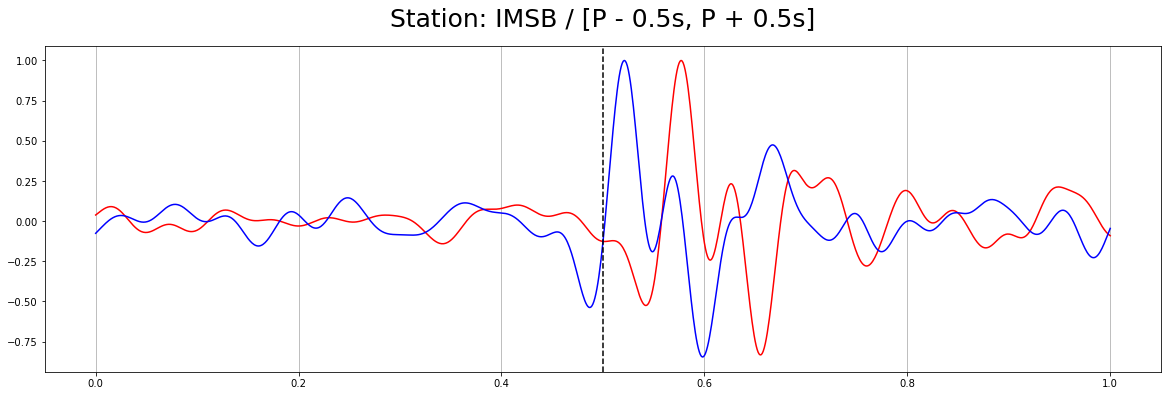

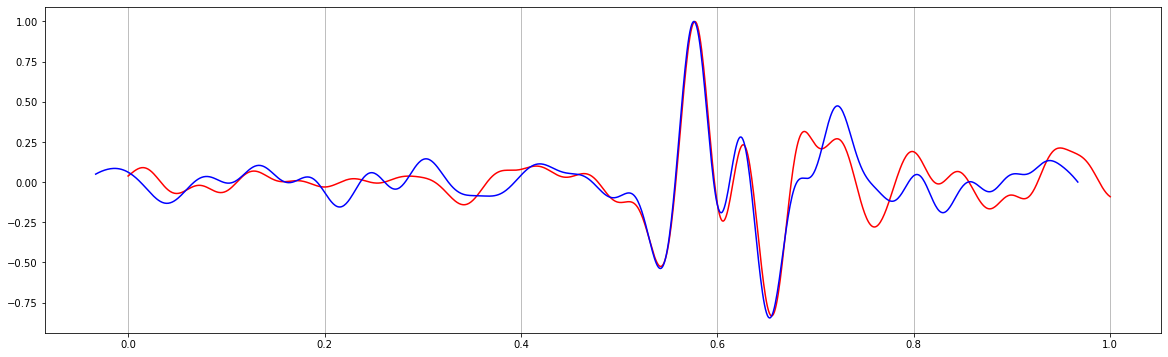

0.055 0.8927883395843949


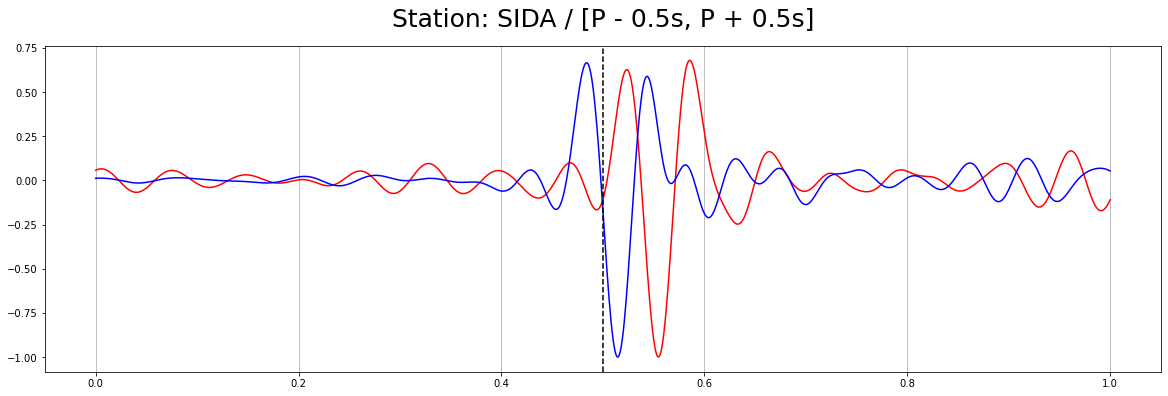

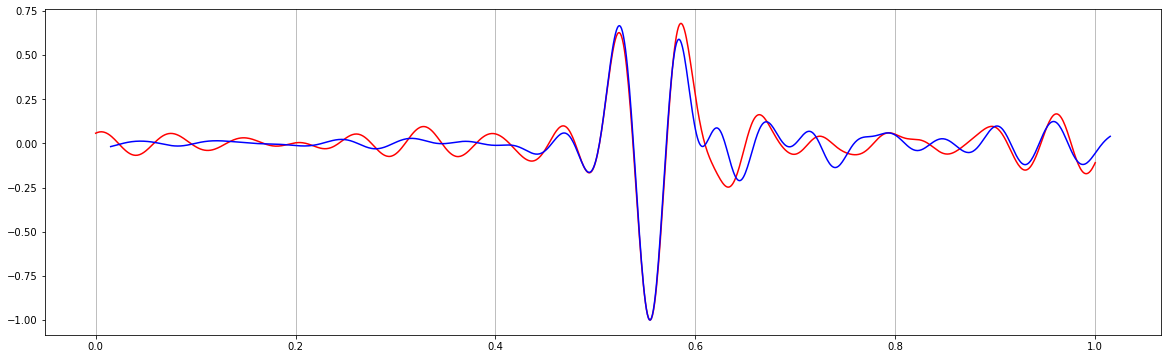

0.04 0.940651594358392


In [34]:
common_path="/home/msseo/works/72.2025_Imsil_swarm/5.Detection_HypoInv/event_waveforms/"
eventdir1, eventdir2="012", "013"
pre_lag, post_lag, margin, shift_samp=0.5, 0.5, 0.5, 500

for station in ["IMSB", "SIDA"]:
    
    try:
        [tr1, tr2, tr1_slice, tr2_slice, time1, time2, ot1, ot2]=cc_window_selection(station, eventdir1, eventdir2, pre_lag, post_lag, common_path, freqmin=5, freqmax=20, interp_samp=1000, comp="Z", plot=True)
        [shift, coeff]=cc_measurement_revised_Pwave(tr1_slice, tr2, pre_lag, post_lag, shift_samp, margin, plot=True)
        print(shift, coeff)
        
    except:
        pass

#### S wave cross-correlation

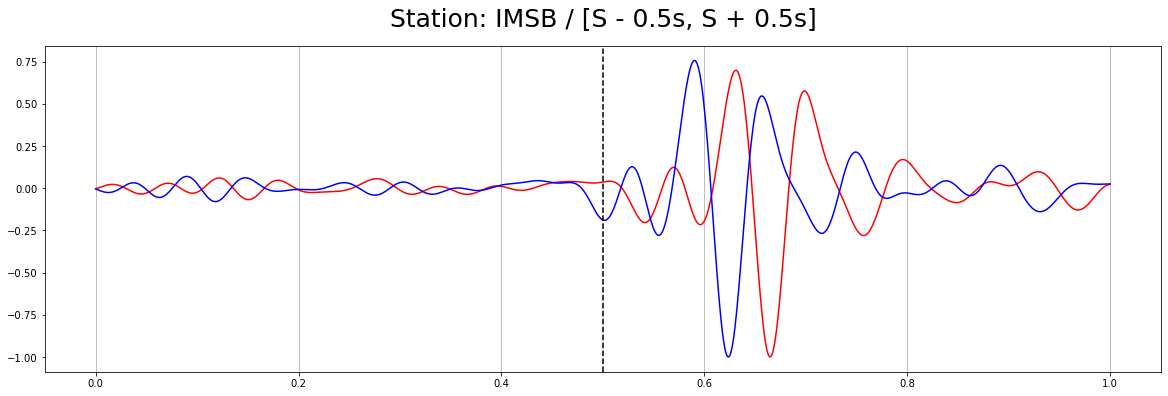

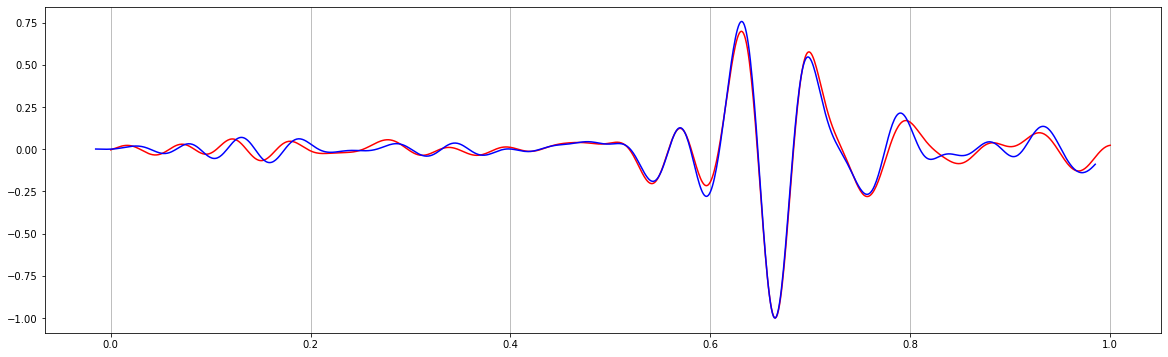

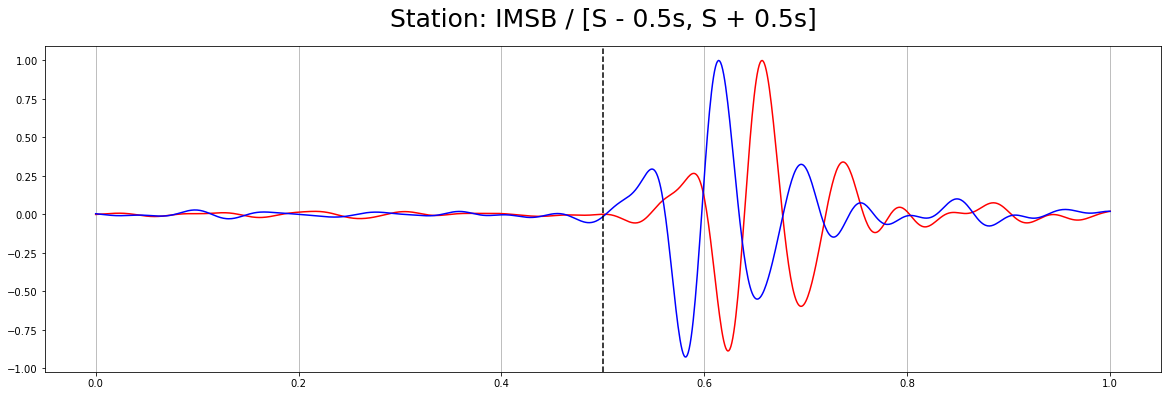

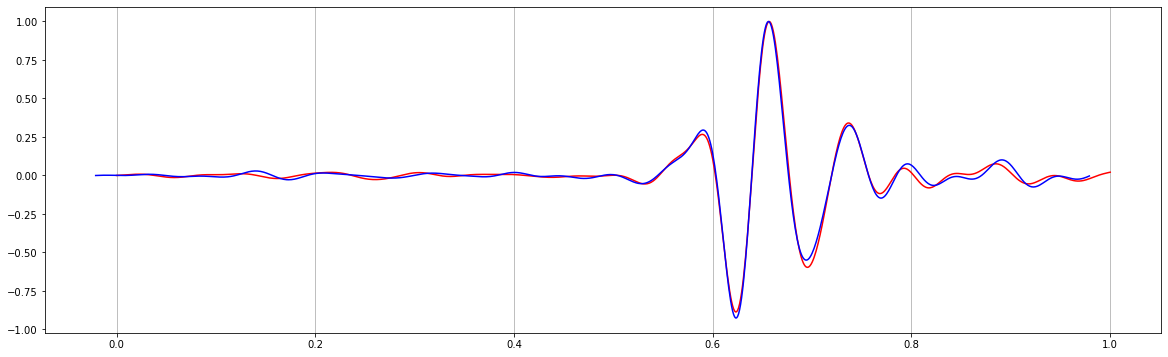

0.042 0.9953831048523007


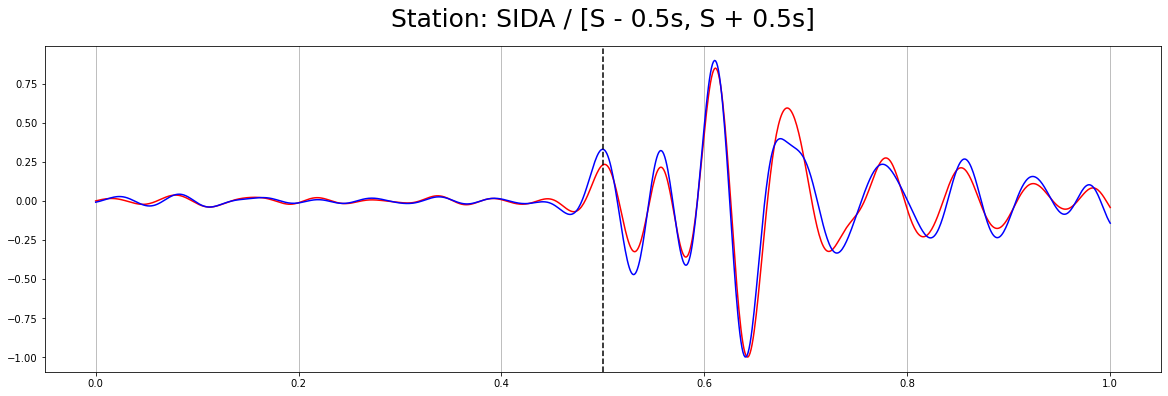

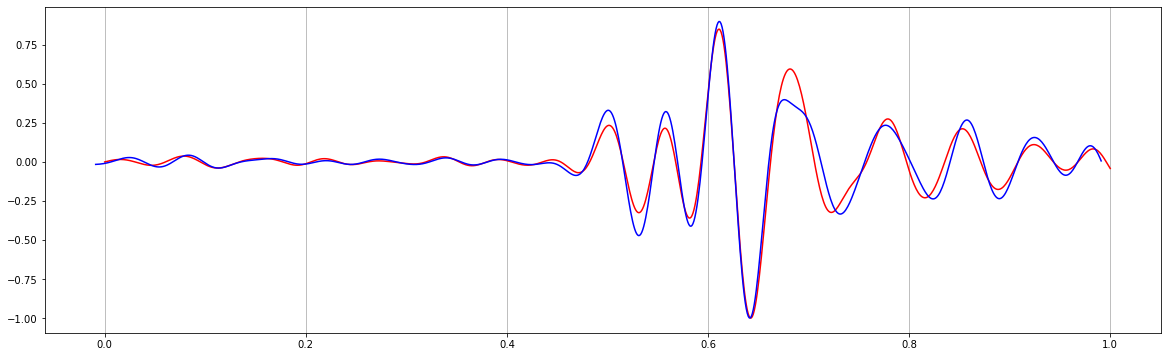

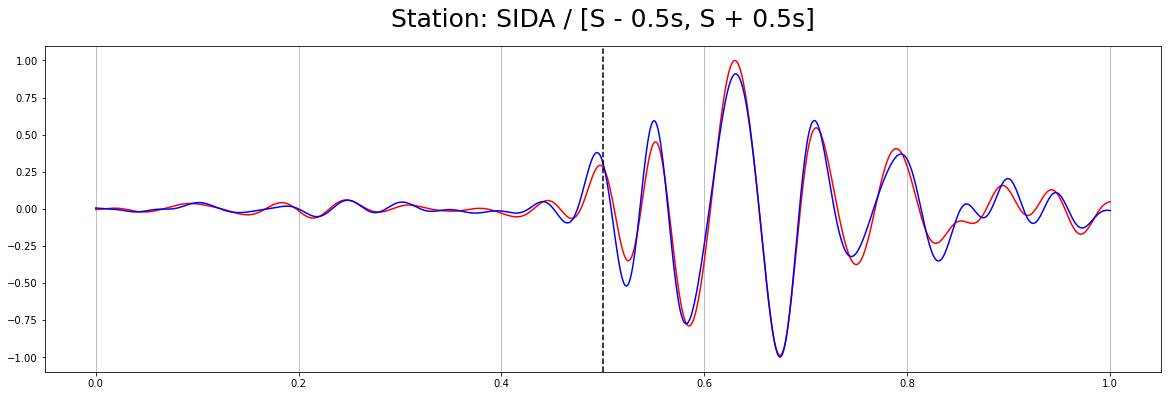

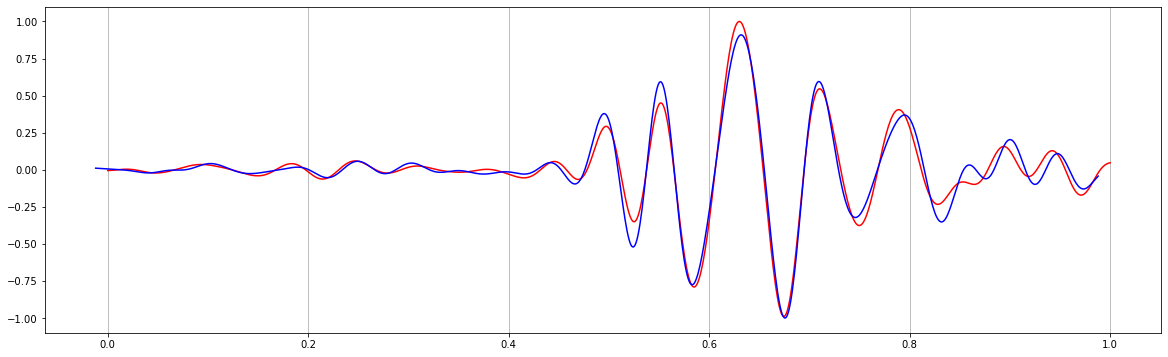

0.001 0.9803928924536927


In [42]:
common_path="/home/msseo/works/72.2025_Imsil_swarm/5.Detection_HypoInv/event_waveforms/"
eventdir1, eventdir2="012", "013"
pre_lag, post_lag, margin, shift_samp=0.5, 0.5, 0.5, 500

for station in ["IMSB", "SIDA"]:
    
    try:
        # Take shift for higher CC
        [tr1, tr2, tr1_slice, tr2_slice, time1, time2, ot1, ot2]=cc_window_selection(station, eventdir1, eventdir2, pre_lag, post_lag, common_path, freqmin=5, freqmax=20, interp_samp=1000, comp="N", plot=True)
        [shift_N, coeff_N]=cc_measurement_revised_Swave(tr1_slice, tr2, pre_lag, post_lag, shift_samp, margin, plot=True)
        
        [tr1, tr2, tr1_slice, tr2_slice, time1, time2, ot1, ot2]=cc_window_selection(station, eventdir1, eventdir2, pre_lag, post_lag, common_path, freqmin=5, freqmax=20, interp_samp=1000, comp="E", plot=True)
        [shift_E, coeff_E]=cc_measurement_revised_Swave(tr1_slice, tr2, pre_lag, post_lag, shift_samp, margin, plot=True)

        if coeff_N >= coeff_E:
            print(shift_N, coeff_N)
        else:
            print(shift_E, coeff_E)
        
    except:
        pass

## Load event table

In [43]:
hypoinv_table=pd.read_csv("/home/msseo/works/72.2025_Imsil_swarm/5.Detection_HypoInv/kim1983/Imsil.sum", sep=",")
hypoinv_table # .head()

,DATE TIME,SEC,LAT,LON,DEPTH,PREF,MAG,NM,NUM,GAP,...,QASR,ID-NUM,LOC,DUR,MAG1,AMP,MAG1.1,EXT,MAG,Unnamed: 23
0,2025/11/02 03:06,7.33,35.5585,127.3033,21.13,,,,9,165,...,D,200000,,,,,,,,NaN
1,2025/11/02 04:13,27.01,35.2357,127.3810,7.87,,,,14,208,...,C,200001,,,,,,,,NaN
2,2025/11/02 06:20,48.35,35.4551,127.3748,1.25,,,,8,113,...,D-,200002,,,,,,,,NaN
3,2025/11/02 07:36,46.77,35.5937,127.2757,27.18,,,,8,120,...,C,200003,,,,,,,,NaN
4,2025/11/02 10:42,33.87,35.5199,127.0868,0.63,,,,7,147,...,C-,200004,,,,,,,,NaN
5,2025/11/02 12:05,49.07,35.5201,127.0960,1.23,,,,8,212,...,D-,200005,,,,,,,,NaN
6,2025/11/02 20:04,19.89,35.5492,127.2775,13.10,,,,10,126,...,C,200006,,,,,,,,NaN
7,2025/11/02 20:05,39.66,35.5471,127.2882,12.02,,,,16,63,...,A,200007,,,,,,,,NaN
8,2025/11/02 20:06,25.36,35.5461,127.2909,12.72,,,,13,132,...,B,200008,,,,,,,,NaN
9,2025/11/02 20:10,44.42,35.5515,127.2887,12.77,,,,19,85,...,B,200009,,,,,,,,NaN


## Calculate for every event pair

In [50]:
common_path="/home/msseo/works/72.2025_Imsil_swarm/5.Detection_HypoInv/event_waveforms/"
event_id_list=np.array(hypoinv_table["    ID-NUM"])%200000
station_list=[]
eventdir_list=np.array(sorted(glob(common_path+"*")))[event_id_list]
for i in tqdm(range(len(eventdir_list))):
    eventdir=eventdir_list[i]
    sacfile_list=glob(eventdir+"/*.SAC")
    for sacfile in sacfile_list:
        station_list.append(sacfile.split("/")[-1].split(".")[2])
station_list=list(set(station_list))
print(len(station_list))

100%|██████████| 39/39 [00:00<00:00, 3864.07it/s]

11


In [52]:
event_pair, event_id=[], []
event_list=np.array(sorted(glob(common_path+"*")))[event_id_list]
for i in range(len(event_list)):
    event_pair.append(event_list[i].split("/")[-1])
    event_id.append(200000+event_id_list[i])

In [55]:
pair_list=[]
for pair in combinations(event_pair, 2):
    pair_list.append(pair)

In [56]:
len(pair_list)

741

### Parallel

In [59]:
def pair_CC_write_file_Pwave(pair):
    
    pair1, pair2=pair[0], pair[1]
    
    # Write to file
    os.makedirs("dt.cc_P", exist_ok=True)
    f=open(f"dt.cc_P/dt.cc_P_{pair1}_{pair2}", 'w')
    f.write(f"#    {event_id[event_pair.index(pair1)]}      {event_id[event_pair.index(pair2)]}       0.0\n")
    
    phase="P"
    margin, shift_samp=0.5, 500
    pre_lag, post_lag=0.5, 0.5
    
    for station in station_list:
        
        try:
            [tr1, tr2, tr1_slice, tr2_slice, time1, time2, ot1, ot2]=cc_window_selection(station, pair1, pair2, pre_lag, post_lag, common_path, freqmin=5, freqmax=20, interp_samp=1000, comp="Z", plot=False)
            [shift, coeff]=cc_measurement_revised_Pwave(tr1_slice, tr2, pre_lag, post_lag, shift_samp, margin, plot=False)
            # print(station, shift, coeff)
            dt=shift
            diff=(time1+dt-ot1)-(time2-ot2) # Differential time
            network=tr1.stats.network
        
            f.write(f"{network}{station}".ljust(6)+" "*5+str(np.round(diff, 5)).ljust(9)+" "*3+str(np.round(coeff, 5)).ljust(11)+" "*4+phase+"\n")
                
        except:
            pass
            
    f.close()    

In [60]:
def pair_CC_write_file_Swave(pair):
    
    pair1, pair2=pair[0], pair[1]
    
    # Write to file
    os.makedirs("dt.cc_S", exist_ok=True)
    f=open(f"dt.cc_S/dt.cc_S_{pair1}_{pair2}", 'w')
    f.write(f"#    {event_id[event_pair.index(pair1)]}      {event_id[event_pair.index(pair2)]}       0.0\n")
    
    phase="S"
    margin, shift_samp=0.5, 500
    pre_lag, post_lag=0.5, 0.5
    
    for station in station_list:
        
        try:
            [tr1, tr2, tr1_slice, tr2_slice, time1, time2, ot1, ot2]=cc_window_selection(station, pair1, pair2, pre_lag, post_lag, common_path, freqmin=5, freqmax=20, interp_samp=1000, comp="N", plot=False)
            [shift_N, coeff_N]=cc_measurement_revised_Swave(tr1_slice, tr2, pre_lag, post_lag, shift_samp, margin, plot=False)
            
            [tr1, tr2, tr1_slice, tr2_slice, time1, time2, ot1, ot2]=cc_window_selection(station, pair1, pair2, pre_lag, post_lag, common_path, freqmin=5, freqmax=20, interp_samp=1000, comp="E", plot=False)
            [shift_E, coeff_E]=cc_measurement_revised_Swave(tr1_slice, tr2, pre_lag, post_lag, shift_samp, margin, plot=False)
            # print(station, shift, coeff)
            if coeff_N >= coeff_E:
                dt, coeff=shift_N, coeff_N
            else:
                dt, coeff=shift_E, coeff_E         

            diff=(time1+dt-ot1)-(time2-ot2) # Differential time
            network=tr1.stats.network
        
            f.write(f"{network}{station}".ljust(6)+" "*5+str(np.round(diff, 5)).ljust(9)+" "*3+str(np.round(coeff, 5)).ljust(11)+" "*4+phase+"\n")
            
        except:
            pass
            
    f.close()    

#### P wave

In [61]:
# Number of cores to use
num_cores=25

if __name__ == "__main__":
    pool=mp.Pool(processes=num_cores)
    pool.map(pair_CC_write_file_Pwave, pair_list)
    pool.close()
    pool.join()

#### S wave

In [62]:
# Number of cores to use
num_cores=25

if __name__ == "__main__":
    pool=mp.Pool(processes=num_cores)
    pool.map(pair_CC_write_file_Swave, pair_list)
    pool.close()
    pool.join()